In [22]:
import pandas as pd
import matplotlib.pyplot as plt

import numpy as np
from prophet import Prophet
from xgboost import XGBRegressor

import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

## Rossmann Store Sales: Initial Data Merging and Diagnostics

I load train.csv and store.csv, parse them, then merge them on Store identifier. I drop the Customers so that we do not use it as a feature. The code prints some statistics from data such as shape, data types, missing values and the percentage of closed and zero sales stores.

In [23]:
train = pd.read_csv('train.csv', parse_dates=['Date'], low_memory=False)
store = pd.read_csv('store.csv')

if 'Customers' in train.columns:
    train = train.drop(columns=['Customers'])

df = pd.merge(train, store, on='Store', how='left')

print("--- Shape ---")
print(df.shape)
print("\n--- Data Types ---")
print(df.dtypes)
print("\n--- Missing Values ---")
print(df.isnull().sum())

pct_open_0 = (df['Open'] == 0).mean()
pct_sales_0 = (df['Sales'] == 0).mean()
print(f"\nShare of rows with Open=0: {pct_open_0:.2%}")
print(f"Share of rows with Sales=0:  {pct_sales_0:.2%}")

--- Shape ---
(1017209, 17)

--- Data Types ---
Store                                 int64
DayOfWeek                             int64
Date                         datetime64[us]
Sales                                 int64
Open                                  int64
Promo                                 int64
StateHoliday                            str
SchoolHoliday                         int64
StoreType                               str
Assortment                              str
CompetitionDistance                 float64
CompetitionOpenSinceMonth           float64
CompetitionOpenSinceYear            float64
Promo2                                int64
Promo2SinceWeek                     float64
Promo2SinceYear                     float64
PromoInterval                           str
dtype: object

--- Missing Values ---
Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Open                  

## Exploratory Data Analysis: Sales Trends and Store Characteristics

1. Total Daily Sales over Time: We show the general trends in the Rossmann stores throughout time.
2. Mean Sales by DayOfWeek: We find the mean sales on each day to see some trends like Sundays and holidays peaks.
3. Mean Sales for Promo 0 and 1: We show avg revenue from promos.
4. Mean Sales by StoreType and Assortment: We show avg sales of different store types and assortments.
5. Number of Open Stores by Day: Show how many stores work each day.

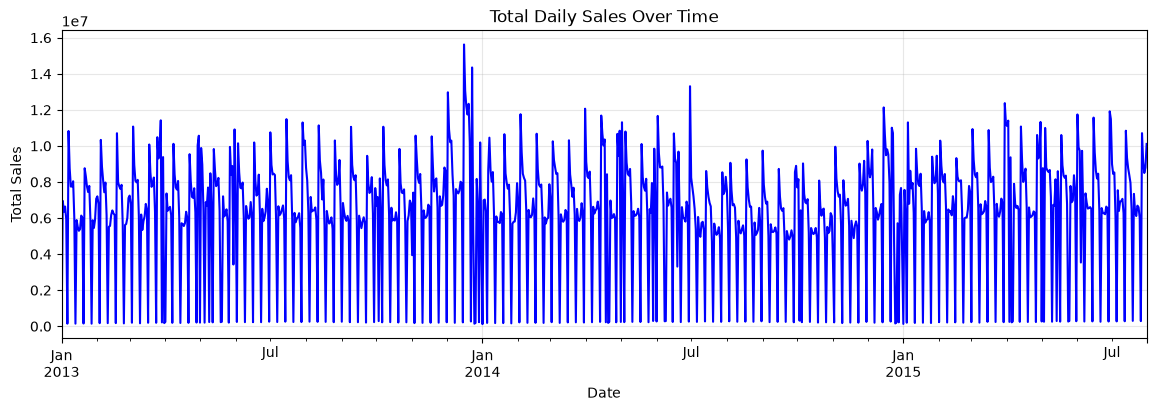

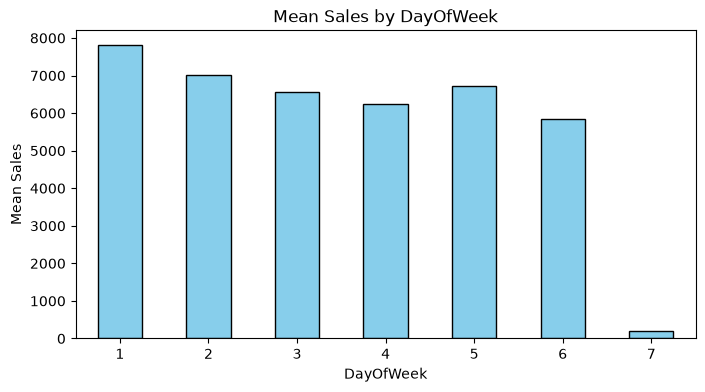

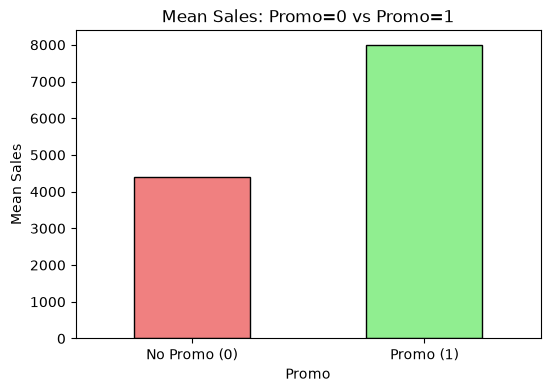

<Figure size 1000x500 with 0 Axes>

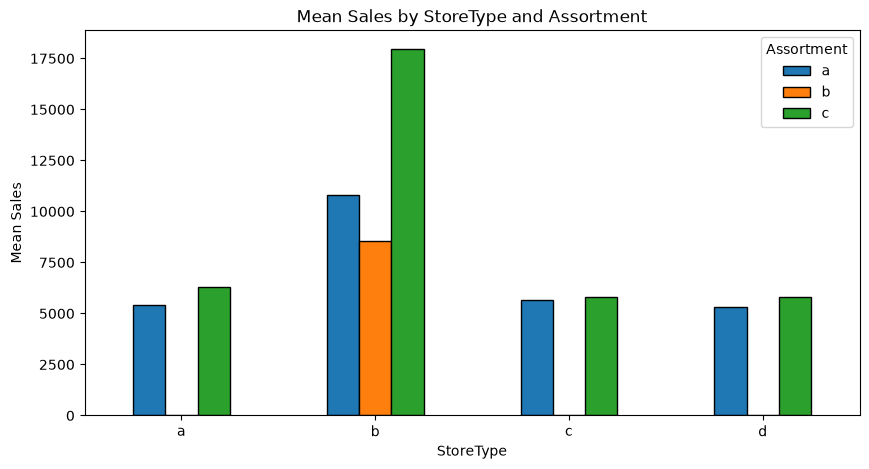

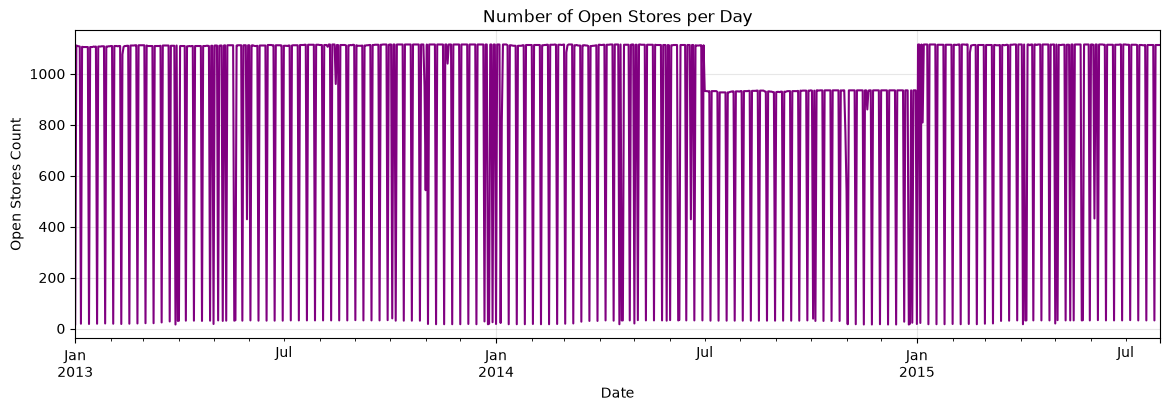

In [24]:
plt.style.use('default')

plt.figure(figsize=(14, 4))
daily_sales = df.groupby('Date')['Sales'].sum()
daily_sales.plot(color='blue')
plt.title('Total Daily Sales Over Time')
plt.ylabel('Total Sales')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
mean_sales_dow = df.groupby('DayOfWeek')['Sales'].mean()
mean_sales_dow.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Mean Sales by DayOfWeek')
plt.ylabel('Mean Sales')
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(6, 4))
mean_sales_promo = df.groupby('Promo')['Sales'].mean()
mean_sales_promo.plot(kind='bar', color=['lightcoral', 'lightgreen'], edgecolor='black')
plt.title('Mean Sales: Promo=0 vs Promo=1')
plt.ylabel('Mean Sales')
plt.xticks(ticks=[0, 1], labels=['No Promo (0)', 'Promo (1)'], rotation=0)
plt.show()

plt.figure(figsize=(10, 5))
sales_type_assort = df.groupby(['StoreType', 'Assortment'])['Sales'].mean().unstack()
sales_type_assort.plot(kind='bar', figsize=(10, 5), edgecolor='black')
plt.title('Mean Sales by StoreType and Assortment')
plt.ylabel('Mean Sales')
plt.xticks(rotation=0)
plt.legend(title='Assortment')
plt.show()

plt.figure(figsize=(14, 4))
open_stores = df.groupby('Date')['Open'].sum()
open_stores.plot(color='purple')
plt.title('Number of Open Stores per Day')
plt.ylabel('Open Stores Count')
plt.grid(True, alpha=0.3)
plt.show()

## Data Preparation: Filtering and Train/Validation Splits

Because on Sundays and some holidays most stores close, it means that the data is artificially skewed. To eliminate this, we take the Mean Sales per Open Store to see the real trends not just the whole skewed story.

In [25]:
df_open = df[(df['Open'] == 1) & (df['Sales'] > 0)].copy()

unique_dates = df_open['Date'].sort_values().unique()
val_start_date = unique_dates[-42]

train_store = df_open[df_open['Date'] < val_start_date].copy()
val_store = df_open[df_open['Date'] >= val_start_date].copy()

prophet_df = df_open.groupby('Date')['Sales'].mean().reset_index()
prophet_df.columns = ['ds', 'y']

train_prophet = prophet_df[prophet_df['ds'] < val_start_date].copy()
val_prophet = prophet_df[prophet_df['ds'] >= val_start_date].copy()

print("--- Store-Level Data Splits ---")
print(f"Training Range:   {train_store['Date'].min().date()} to {train_store['Date'].max().date()}")
print(f"Validation Range: {val_store['Date'].min().date()} to {val_store['Date'].max().date()}")

print("\n--- Prophet Data Splits ---")
print(f"Training Range:   {train_prophet['ds'].min().date()} to {train_prophet['ds'].max().date()}")
print(f"Validation Range: {val_prophet['ds'].min().date()} to {val_prophet['ds'].max().date()}")

--- Store-Level Data Splits ---
Training Range:   2013-01-01 to 2015-06-19
Validation Range: 2015-06-20 to 2015-07-31

--- Prophet Data Splits ---
Training Range:   2013-01-01 to 2015-06-19
Validation Range: 2015-06-20 to 2015-07-31


## Time Series Forecasting: Prophet Baseline Model


We use Prophet to see the trends for weekly and yearly basis. Then check for MAE,MAPE,RMSPE.

23:18:55 - cmdstanpy - INFO - Chain [1] start processing
23:18:55 - cmdstanpy - INFO - Chain [1] done processing


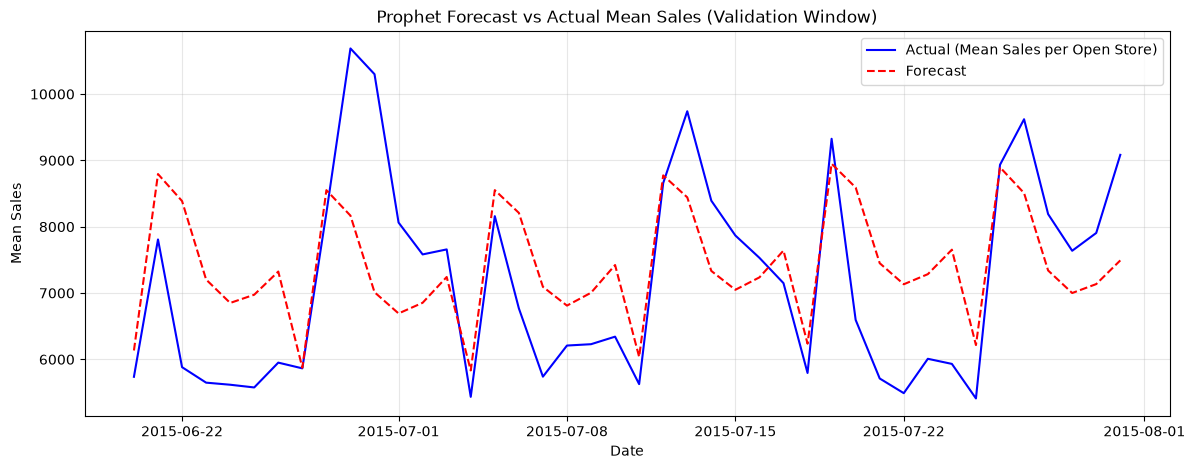

--- Store-Level Validation Metrics ---
MAE:   2240.27
MAPE:  0.3888 (38.88%)
RMSPE: 0.5715 (57.15%)


In [26]:
model = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
model.fit(train_prophet)

forecast = model.predict(val_prophet[['ds']])

plt.figure(figsize=(14, 5))
plt.plot(val_prophet['ds'], val_prophet['y'], label='Actual (Mean Sales per Open Store)', color='blue')
plt.plot(forecast['ds'], forecast['yhat'], label='Forecast', color='red', linestyle='--')
plt.title('Prophet Forecast vs Actual Mean Sales (Validation Window)')
plt.xlabel('Date')
plt.ylabel('Mean Sales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

val_store_merged = pd.merge(val_store, forecast[['ds', 'yhat']], left_on='Date', right_on='ds', how='left')

val_eval = val_store_merged[val_store_merged['Sales'] > 0].copy()

def get_mae(y, yhat):
    return np.mean(np.abs(y - yhat))

def get_mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y))

def get_rmspe(y, yhat):
    return np.sqrt(np.mean(((y - yhat) / y) ** 2))

# 6. Compute and print metrics at the store-day level
y_true = val_eval['Sales']
y_pred = val_eval['yhat']

mae = get_mae(y_true, y_pred)
mape = get_mape(y_true, y_pred)
rmspe = get_rmspe(y_true, y_pred)

print("--- Store-Level Validation Metrics ---")
print(f"MAE:   {mae:.2f}")
print(f"MAPE:  {mape:.4f} ({mape:.2%})")
print(f"RMSPE: {rmspe:.4f} ({rmspe:.2%})")

The next piece of code prepares the data for XGBoost and have functions that ease our work

In [27]:
def prepare_prophet_residual_dataset(train_df, val_df, store_df, prophet_forecast_df):
    """Prepares training and validation feature matrices for residual modeling

    after Prophet predictions.
    """
    join_keys = (
        ["Store", "Date"]
        if "Store" in prophet_forecast_df.columns
        else ["Date"]
    )

    train_df["Date"] = pd.to_datetime(train_df["Date"])
    val_df["Date"] = pd.to_datetime(val_df["Date"])
    prophet_forecast_df["ds"] = pd.to_datetime(prophet_forecast_df["ds"])

    train_df = train_df.merge(
        prophet_forecast_df[join_keys + ["yhat"]],
        left_on=join_keys,
        right_on=["Store", "ds"] if "Store" in join_keys else ["ds"],
        how="left",
    ).rename(columns={"yhat": "prophet_yhat"})

    val_df = val_df.merge(
        prophet_forecast_df[join_keys + ["yhat"]],
        left_on=join_keys,
        right_on=["Store", "ds"] if "Store" in join_keys else ["ds"],
        how="left",
    ).rename(columns={"yhat": "prophet_yhat"})

    train_df["y_resid"] = train_df["Sales"] - train_df["prophet_yhat"]

    train_df = train_df.merge(store_df, on="Store", how="left")
    val_df = val_df.merge(store_df, on="Store", how="left")

    month_map = {
        1: "Jan",
        2: "Feb",
        3: "Mar",
        4: "Apr",
        5: "May",
        6: "Jun",
        7: "Jul",
        8: "Aug",
        9: "Sept",
        10: "Oct",
        11: "Nov",
        12: "Dec",
    }

    def extract_features(df):
        df = df.copy()

        df["Month"] = df["Date"].dt.month
        df["Year"] = df["Date"].dt.year
        df["DayOfWeek"] = df["Date"].dt.dayofweek + 1

        median_dist = store_df["CompetitionDistance"].median()
        df["CompetitionDistance"] = df["CompetitionDistance"].fillna(
            median_dist
        )

        comp_open_date = pd.to_datetime(
            df["CompetitionOpenSinceYear"].astype("str").str.split(".").str[0]
            + "-"
            + df["CompetitionOpenSinceMonth"]
            .astype("str")
            .str.split(".")
            .str[0]
            + "-01",
            errors="coerce",
        )

        df["MonthsSinceCompetition"] = (
            (df["Date"].dt.year - comp_open_date.dt.year) * 12
            + (df["Date"].dt.month - comp_open_date.dt.month)
        ).fillna(0)
        df["MonthsSinceCompetition"] = df["MonthsSinceCompetition"].apply(
            lambda x: max(0, x)
        )

        promo2_start_date = pd.to_datetime(
            df["Promo2SinceYear"].astype("str").str.split(".").str[0]
            + df["Promo2SinceWeek"]
            .astype("str")
            .str.split(".")
            .str[0]
            .str.zfill(2)
            + "-1",
            format="%Y%W-%w",
            errors="coerce",
        )

        df["MonthStr"] = df["Month"].map(month_map)

        def check_promo2_active(row, p2_start):
            if row["Promo2"] != 1 or pd.isna(p2_start):
                return 0
            if row["Date"] < p2_start:
                return 0
            if (
                pd.notna(row["PromoInterval"])
                and row["MonthStr"] in row["PromoInterval"].split(",")
            ):
                return 1
            return 0

        df["IsPromo2Active"] = [
            check_promo2_active(r, start)
            for r, start in zip(
                df[["Promo2", "Date", "PromoInterval", "MonthStr"]].to_dict(
                    "records"
                ),
                promo2_start_date,
            )
        ]

        state_holiday_map = {"0": 0, 0: 0, "a": 1, "b": 2, "c": 3}
        store_type_map = {"a": 1, "b": 2, "c": 3, "d": 4}
        assortment_map = {"a": 1, "b": 2, "c": 3}

        df["StateHoliday"] = (
            df["StateHoliday"].map(state_holiday_map).fillna(0).astype(int)
        )
        df["SchoolHoliday"] = df["SchoolHoliday"].astype(int)
        df["StoreType"] = df["StoreType"].map(store_type_map).fillna(0)
        df["Assortment"] = df["Assortment"].map(assortment_map).fillna(0)

        feature_cols = [
            "Promo",
            "Promo2",
            "IsPromo2Active",
            "StateHoliday",
            "SchoolHoliday",
            "DayOfWeek",
            "Month",
            "StoreType",
            "Assortment",
            "CompetitionDistance",
            "MonthsSinceCompetition",
        ]

        return df[feature_cols]

    X_train = extract_features(train_df)
    y_resid_train = train_df["y_resid"]
    X_val = extract_features(val_df)

    return X_train, y_resid_train, X_val

## Hybrid Residual Modeling with XGBoost

Because Prophet sees the general trends, we use XGBRegressor to see the store-specific dynamics to improve the algorithm

--- Hybrid Model Store-Level Validation Metrics ---
MAE:   1360.66
MAPE:  0.2257 (22.57%)
RMSPE: 0.3254 (32.54%)


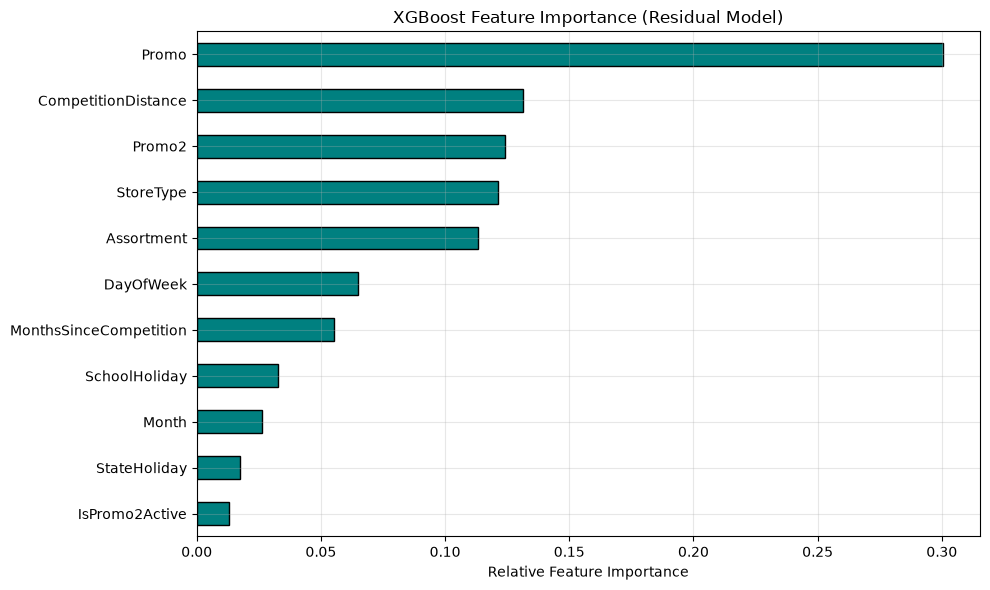

In [28]:
in_sample_forecast = model.predict(train_prophet[['ds']])[['ds', 'yhat']].rename(columns={'yhat': 'prophet_yhat'})
out_sample_forecast = forecast[['ds', 'yhat']].rename(columns={'yhat': 'prophet_yhat'})

train_store_merged = pd.merge(train_store, in_sample_forecast, left_on='Date', right_on='ds', how='left')
val_store_merged = pd.merge(val_store, out_sample_forecast, left_on='Date', right_on='ds', how='left')

y_resid_train = train_store_merged['Sales'] - train_store_merged['prophet_yhat']

def extract_features(df):
    X = pd.DataFrame(index=df.index)
    
    X['Promo'] = df['Promo'].values
    X['Promo2'] = df['Promo2'].values
    
    month_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 
                 7: 'Jul', 8: 'Aug', 9: 'Sept', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
    month_name = df['Date'].dt.month.map(month_map)
    year = df['Date'].dt.year
    week = df['Date'].dt.isocalendar().week
    
    after_start = (year > df['Promo2SinceYear']) | ((year == df['Promo2SinceYear']) & (week >= df['Promo2SinceWeek']))
    
    in_interval = np.array([
        False if pd.isna(interval) else m in interval.split(',')
        for m, interval in zip(month_name, df['PromoInterval'])
    ])
    
    X['IsPromo2Active'] = ((df['Promo2'] == 1) & after_start & in_interval).astype(int).values
    
    state_holiday_map = {'0': 0, 0: 0, 'a': 1, 'b': 2, 'c': 3}
    store_type_map = {'a': 0, 'b': 1, 'c': 2, 'd': 3}
    assortment_map = {'a': 0, 'b': 1, 'c': 2}
    
    X['StateHoliday'] = df['StateHoliday'].map(state_holiday_map).fillna(0).astype(int).values
    X['SchoolHoliday'] = df['SchoolHoliday'].astype(int).values
    X['DayOfWeek'] = df['DayOfWeek'].values
    X['Month'] = df['Date'].dt.month.values
    X['StoreType'] = df['StoreType'].map(store_type_map).fillna(0).astype(int).values
    X['Assortment'] = df['Assortment'].map(assortment_map).fillna(0).astype(int).values
    
    comp_dist_median = df['CompetitionDistance'].median()
    X['CompetitionDistance'] = df['CompetitionDistance'].fillna(comp_dist_median).values
    
    months_since = 12 * (df['Date'].dt.year - df['CompetitionOpenSinceYear']) + (df['Date'].dt.month - df['CompetitionOpenSinceMonth'])
    X['MonthsSinceCompetition'] = months_since.apply(lambda x: 0 if pd.isna(x) or x < 0 else int(x)).values
    
    return X

X_train = extract_features(train_store_merged)
X_val = extract_features(val_store_merged)

xgb_model = XGBRegressor(n_estimators=150, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_resid_train)

predicted_residual = xgb_model.predict(X_val)
hybrid_pred = val_store_merged['prophet_yhat'] + predicted_residual

val_eval = val_store_merged[val_store_merged['Sales'] > 0].copy()
hybrid_pred_eval = hybrid_pred[val_store_merged['Sales'] > 0]

y_val = val_eval['Sales'].values

mae_hybrid = np.mean(np.abs(y_val - hybrid_pred_eval))
mape_hybrid = np.mean(np.abs((y_val - hybrid_pred_eval) / y_val))
rmspe_hybrid = np.sqrt(np.mean(((y_val - hybrid_pred_eval) / y_val) ** 2))

print("--- Hybrid Model Store-Level Validation Metrics ---")
print(f"MAE:   {mae_hybrid:.2f}")
print(f"MAPE:  {mape_hybrid:.4f} ({mape_hybrid:.2%})")
print(f"RMSPE: {rmspe_hybrid:.4f} ({rmspe_hybrid:.2%})")

plt.figure(figsize=(10, 6))
importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values()
importances.plot(kind='barh', color='teal', edgecolor='black')
plt.title('XGBoost Feature Importance (Residual Model)')
plt.xlabel('Relative Feature Importance')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Direct XGBoost Model (No Prophet Involvement)

This is the only-XGBoost model part

In [29]:
min_date = df_open['Date'].min()

def extract_direct_features(df_input):
    X = pd.DataFrame(index=df_input.index)
    
    X['Promo'] = df_input['Promo'].values
    X['Promo2'] = df_input['Promo2'].values
    
    month_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 
                 7: 'Jul', 8: 'Aug', 9: 'Sept', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
    month_name = df_input['Date'].dt.month.map(month_map)
    year = df_input['Date'].dt.year
    week = df_input['Date'].dt.isocalendar().week
    
    after_start = (year > df_input['Promo2SinceYear']) | ((year == df_input['Promo2SinceYear']) & (week >= df_input['Promo2SinceWeek']))
    in_interval = np.array([
        False if pd.isna(interval) else m in interval.split(',')
        for m, interval in zip(month_name, df_input['PromoInterval'])
    ])
    X['IsPromo2Active'] = ((df_input['Promo2'] == 1) & after_start & in_interval).astype(int).values
    
    state_holiday_map = {'0': 0, 0: 0, 'a': 1, 'b': 2, 'c': 3}
    store_type_map = {'a': 0, 'b': 1, 'c': 2, 'd': 3}
    assortment_map = {'a': 0, 'b': 1, 'c': 2}
    
    X['StateHoliday'] = df_input['StateHoliday'].map(state_holiday_map).fillna(0).astype(int).values
    X['SchoolHoliday'] = df_input['SchoolHoliday'].astype(int).values
    X['StoreType'] = df_input['StoreType'].map(store_type_map).fillna(0).astype(int).values
    X['Assortment'] = df_input['Assortment'].map(assortment_map).fillna(0).astype(int).values
    
    comp_dist_median = df_input['CompetitionDistance'].median()
    X['CompetitionDistance'] = df_input['CompetitionDistance'].fillna(comp_dist_median).values
    
    months_since = 12 * (df_input['Date'].dt.year - df_input['CompetitionOpenSinceYear']) + (df_input['Date'].dt.month - df_input['CompetitionOpenSinceMonth'])
    X['MonthsSinceCompetition'] = months_since.apply(lambda x: 0 if pd.isna(x) or x < 0 else int(x)).values
    
    X['DayOfWeek'] = df_input['DayOfWeek'].values
    X['Month'] = df_input['Date'].dt.month.values
    X['DayOfYear'] = df_input['Date'].dt.dayofyear.values
    X['WeekOfYear'] = df_input['Date'].dt.isocalendar().week.astype(int).values
    X['TimeIndex'] = (df_input['Date'] - min_date).dt.days.values
    
    return X

X_train_direct = extract_direct_features(train_store)
y_train_direct = train_store['Sales'].values

X_val_direct = extract_direct_features(val_store)
y_val_direct = val_store['Sales'].values

xgb_direct = XGBRegressor(n_estimators=150, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1)
xgb_direct.fit(X_train_direct, y_train_direct)

direct_preds = xgb_direct.predict(X_val_direct)

val_mask = val_store['Sales'] > 0
y_val_eval = y_val_direct[val_mask]
direct_preds_eval = direct_preds[val_mask]

mae_direct = np.mean(np.abs(y_val_eval - direct_preds_eval))
mape_direct = np.mean(np.abs((y_val_eval - direct_preds_eval) / y_val_eval))
rmspe_direct = np.sqrt(np.mean(((y_val_eval - direct_preds_eval) / y_val_eval) ** 2))

print("--- Direct XGBoost Validation Metrics ---")
print(f"MAE:   {mae_direct:.2f}")
print(f"MAPE:  {mape_direct:.4f} ({mape_direct:.2%})")
print(f"RMSPE: {rmspe_direct:.4f} ({rmspe_direct:.2%})")

--- Direct XGBoost Validation Metrics ---
MAE:   1384.73
MAPE:  0.2209 (22.09%)
RMSPE: 0.3152 (31.52%)


## Final Model Evaluation & Comparison

We evaluated the Prophet, XGBoost and the Hybrid Model.

=== Model Comparison Summary ===


,MAE,MAPE,RMSPE
Prophet alone,2240.268437,38.88%,57.15%
End-to-end XGBoost,1384.725145,22.09%,31.52%
Hybrid,1360.655178,22.57%,32.54%



=== Percentage Improvement of Hybrid Model ===

--- Improvement over Prophet alone ---
MAE: +39.26%
MAPE: +41.96%
RMSPE: +43.07%

--- Improvement over End-to-end XGBoost ---
MAE: +1.74%
MAPE: -2.18%
RMSPE: -3.23%


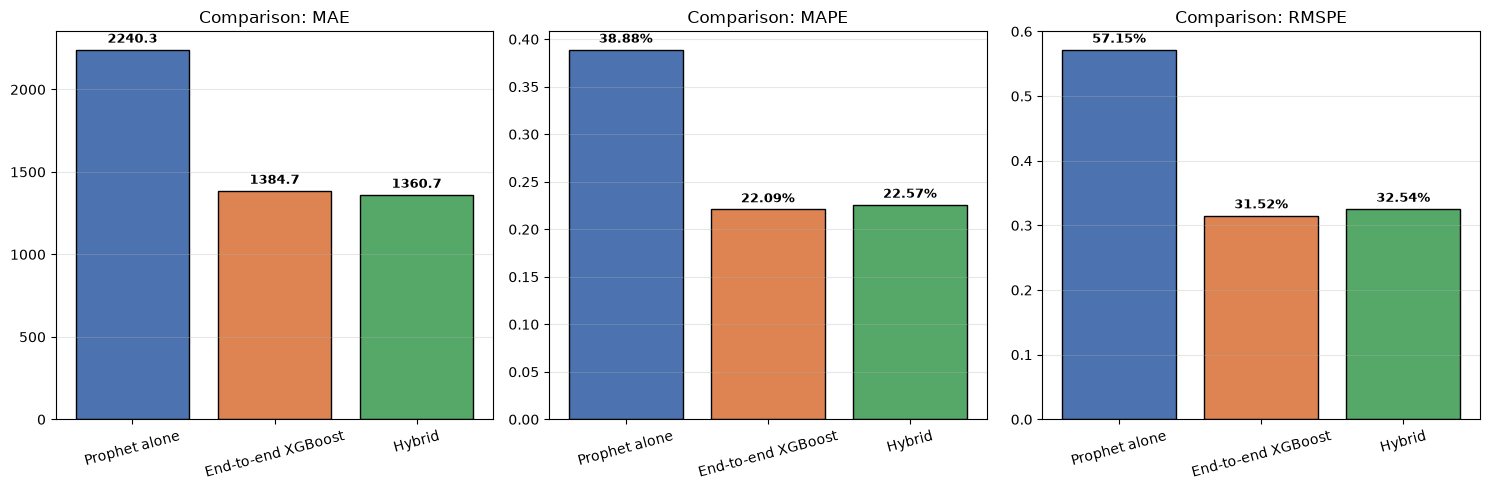

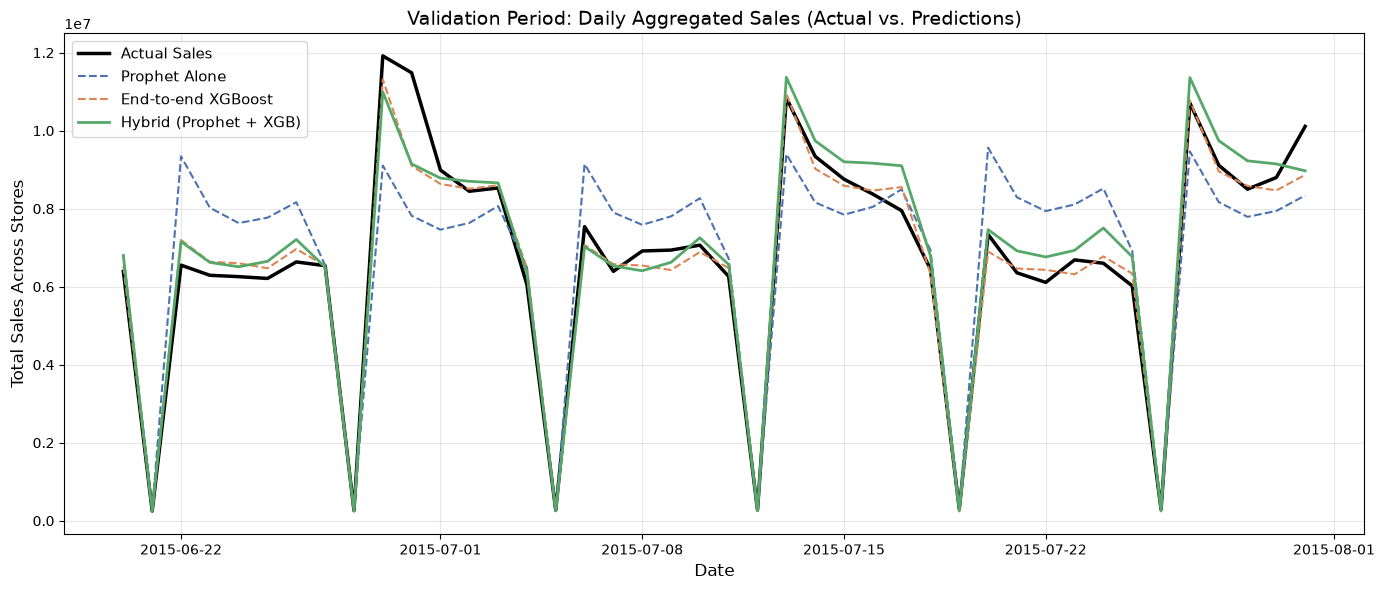

In [30]:
val_mask = val_store_merged['Sales'] > 0

y_true = val_store_merged.loc[val_mask, 'Sales'].values
pred_prophet = val_store_merged.loc[val_mask, 'prophet_yhat'].values
pred_xgb_direct = direct_preds[val_mask]
pred_hybrid = hybrid_pred[val_mask]

def calc_metrics(y_real, y_pred):
    mae = np.mean(np.abs(y_real - y_pred))
    mape = np.mean(np.abs((y_real - y_pred) / y_real))
    rmspe = np.sqrt(np.mean(((y_real - y_pred) / y_real) ** 2))
    return mae, mape, rmspe

metrics = {
    'Prophet alone': calc_metrics(y_true, pred_prophet),
    'End-to-end XGBoost': calc_metrics(y_true, pred_xgb_direct),
    'Hybrid': calc_metrics(y_true, pred_hybrid)
}

results_df = pd.DataFrame(metrics, index=['MAE', 'MAPE', 'RMSPE']).T
results_df['MAPE'] = results_df['MAPE'].apply(lambda x: f"{x:.2%}")
results_df['RMSPE'] = results_df['RMSPE'].apply(lambda x: f"{x:.2%}")

print("=== Model Comparison Summary ===")
display(results_df)

raw_metrics = {
    'Prophet alone': calc_metrics(y_true, pred_prophet),
    'End-to-end XGBoost': calc_metrics(y_true, pred_xgb_direct),
    'Hybrid': calc_metrics(y_true, pred_hybrid)
}

print("\n=== Percentage Improvement of Hybrid Model ===")
for baseline in ['Prophet alone', 'End-to-end XGBoost']:
    print(f"\n--- Improvement over {baseline} ---")
    for idx, metric_name in enumerate(['MAE', 'MAPE', 'RMSPE']):
        base_val = raw_metrics[baseline][idx]
        hybrid_val = raw_metrics['Hybrid'][idx]
        pct_imp = (base_val - hybrid_val) / base_val * 100
        print(f"{metric_name}: {pct_imp:+.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metric_names = ['MAE', 'MAPE', 'RMSPE']

for i, metric in enumerate(metric_names):
    vals = [raw_metrics[m][i] for m in raw_metrics.keys()]
    bars = axes[i].bar(raw_metrics.keys(), vals, color=['#4C72B0', '#DD8452', '#55A868'], edgecolor='black')
    axes[i].set_title(f'Comparison: {metric}')
    
    axes[i].tick_params(axis='x', rotation=15)
    axes[i].grid(True, alpha=0.3, axis='y')
    
    for bar in bars:
        height = bar.get_height()
        fmt = f"{height:.2%}" if metric in ['MAPE', 'RMSPE'] else f"{height:.1f}"
        axes[i].annotate(fmt,
                         xy=(bar.get_x() + bar.get_width() / 2, height),
                         xytext=(0, 3),  
                         textcoords="offset points",
                         ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

daily_eval = val_store_merged[val_mask].copy()
daily_eval['pred_prophet'] = pred_prophet
daily_eval['pred_xgb_direct'] = pred_xgb_direct
daily_eval['pred_hybrid'] = pred_hybrid

daily_summary = daily_eval.groupby('Date')[['Sales', 'pred_prophet', 'pred_xgb_direct', 'pred_hybrid']].sum()

plt.figure(figsize=(14, 6))
plt.plot(daily_summary.index, daily_summary['Sales'], label='Actual Sales', color='black', linewidth=2.5)
plt.plot(daily_summary.index, daily_summary['pred_prophet'], label='Prophet Alone', color='#4C72B0', linestyle='--')
plt.plot(daily_summary.index, daily_summary['pred_xgb_direct'], label='End-to-end XGBoost', color='#DD8452', linestyle='--')
plt.plot(daily_summary.index, daily_summary['pred_hybrid'], label='Hybrid (Prophet + XGB)', color='#55A868', linewidth=2)

plt.title('Validation Period: Daily Aggregated Sales (Actual vs. Predictions)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Sales Across Stores', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Conclusion

The difference between the Hybrid model and Prophet alone is massive.
However, when compared to XGBoost only, the Hybrid model doesn't show big difference.

Therefore, I would rather use simple XGBoost instead of trying to combine the Prophet and XGBoost.